In [1]:
BASE_INPUT_DIR = '../testing_output/'

OUTPUT_DIR = '../onset_apex'

ONSET_INTENSITY_THRESHOLD = 0.15
RESIZE_DIMENSIONS = (256, 256)

In [2]:
import os
import shutil
import torch
import numpy as np
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
from facenet_pytorch import MTCNN

def setup_detector():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Menggunakan perangkat: {device}")
    print("Menyiapkan detektor wajah (MTCNN)...")
    face_detector = MTCNN(keep_all=True, device=device, select_largest=False)
    print("Detektor siap.")
    return face_detector, device

/home/ryuko/Documents/codes/Skripsi/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def find_onset_apex(all_landmarks, threshold):
    first_valid_landmarks = None
    for lm in all_landmarks:
        if lm is not None:
            try:
                first_valid_landmarks = np.array(lm, dtype=np.float32)
                if first_valid_landmarks.shape == (5, 2):
                    break
                else:
                    first_valid_landmarks = None
            except (ValueError, IndexError):
                continue

    if first_valid_landmarks is None:
        return None, None, np.array([])

    reference_landmarks = first_valid_landmarks
    displacements = []

    for landmarks in all_landmarks:
        if landmarks is None:
            displacements.append(0)
            continue

        try:
            current_landmarks = np.array(landmarks, dtype=np.float32)
            if current_landmarks.shape != (5, 2):
                displacements.append(0)
                continue
            dist = np.linalg.norm(current_landmarks - reference_landmarks, axis=1).mean()
            displacements.append(dist)
        except (ValueError, IndexError):
            displacements.append(0)
            continue

    intensity_signal = np.array(displacements)
    if intensity_signal.size == 0 or np.max(intensity_signal) == 0:
        return None, None, intensity_signal

    apex_index = np.argmax(intensity_signal)
    apex_intensity = intensity_signal[apex_index]
    onset_threshold_value = apex_intensity * threshold

    candidate_indices = np.where(intensity_signal[:apex_index + 1] >= onset_threshold_value)[0]
    onset_index = candidate_indices[0] if len(candidate_indices) > 0 else 0

    return onset_index, apex_index, intensity_signal

In [ ]:
def analyze_and_visualize(input_path, output_path, detector, threshold, resize_dim):
    if not os.path.isdir(input_path):
        return

    image_files = sorted([f for f in os.listdir(input_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    if not image_files:
        return

    image_paths = [os.path.join(input_path, f) for f in image_files]

    try:
        all_landmarks = []
        for p in image_paths:
            img = Image.open(p).resize(resize_dim)
            _, _, landmarks_list = detector.detect(img, landmarks=True)
            all_landmarks.append(landmarks_list[0] if landmarks_list is not None else None)

        onset_idx, apex_idx, signal = find_onset_apex(all_landmarks, threshold)

        if onset_idx is None or apex_idx is None or onset_idx >= apex_idx:
            print(f"\n[INFO] Rentang ekspresi tidak valid untuk '{os.path.basename(input_path)}'. Melewati.")
            return

        plt.figure(figsize=(15, 6))
        plt.plot(signal, label='Intensitas Ekspresi', color='royalblue')
        plt.axvline(x=onset_idx, color='green', linestyle='--', label=f'Onset (Frame {onset_idx})')
        plt.axvline(x=apex_idx, color='red', linestyle='--', label=f'Apex (Frame {apex_idx})')
        plt.title(f'Analisis Intensitas Ekspresi untuk "{os.path.basename(input_path)}"', fontsize=16)
        plt.xlabel('Indeks Frame', fontsize=12)
        plt.ylabel('Rata-rata Perpindahan Landmark', fontsize=12)
        plt.legend()
        plt.grid(True, which='both', linestyle='--', linewidth=0.5)
        plt.show()

        print(f"[KESIMPULAN] Rentang terdeteksi: Frame {onset_idx} (Onset) hingga {apex_idx} (Apex).")

        os.makedirs(output_path, exist_ok=True)

        selected_files = image_files[onset_idx : apex_idx + 1]
        for file_name in selected_files:
            shutil.copy2(os.path.join(input_path, file_name), os.path.join(output_path, file_name))

        print(f"Berhasil! {len(selected_files)} frame yang relevan telah disalin.")

    except Exception as e:
        print(f"\n[ERROR] Terjadi kesalahan saat memproses '{os.path.basename(input_path)}': {e}")
    finally:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

Menggunakan perangkat: cuda
Menyiapkan detektor wajah (MTCNN)...
Detektor siap.

==================== MEMPROSES KATEGORI: SEDANG ====================


Analisis di 'Sedang':   0%|          | 0/10 [00:00<?, ?it/s]

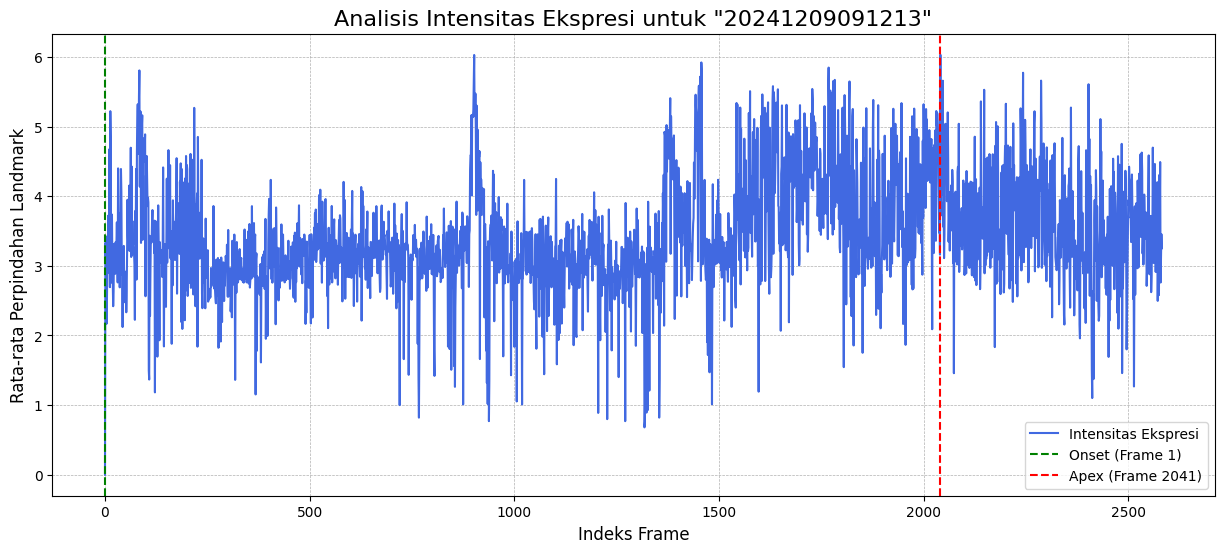

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 2041 (Apex).


Analisis di 'Sedang':  10%|█         | 1/10 [00:53<08:04, 53.86s/it]

Berhasil! 2041 frame yang relevan telah disalin.


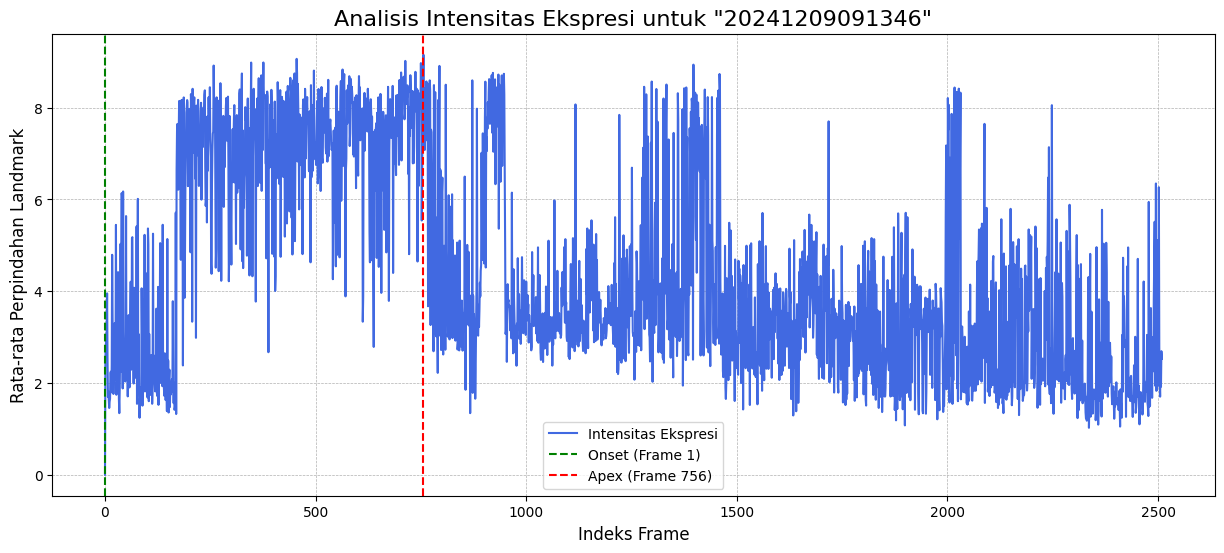

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 756 (Apex).


Analisis di 'Sedang':  20%|██        | 2/10 [01:51<07:28, 56.06s/it]

Berhasil! 756 frame yang relevan telah disalin.


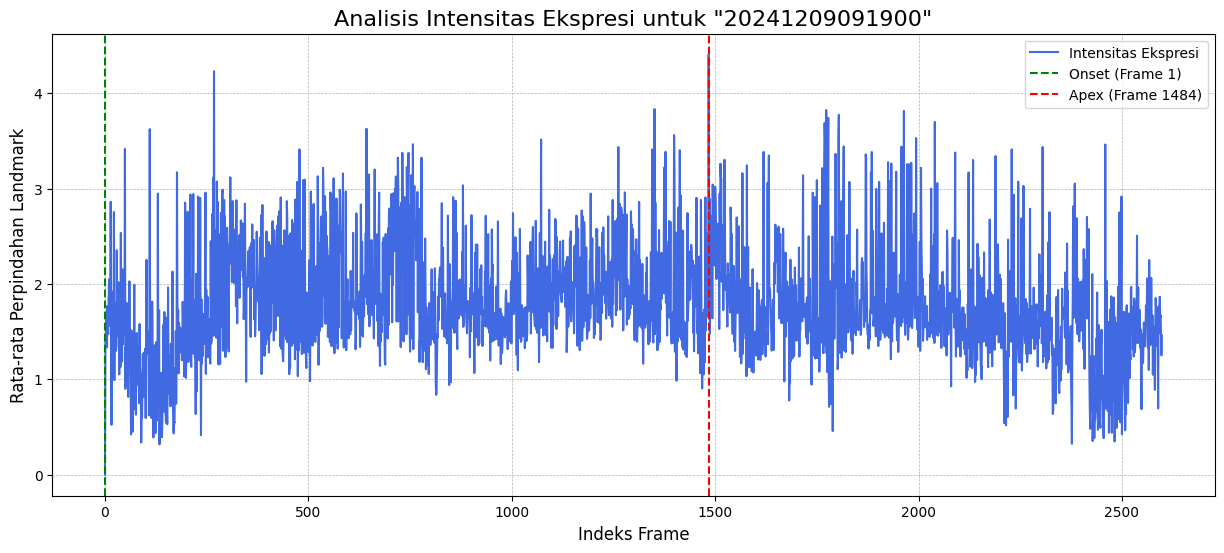

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1484 (Apex).


Analisis di 'Sedang':  30%|███       | 3/10 [02:47<06:33, 56.24s/it]

Berhasil! 1484 frame yang relevan telah disalin.


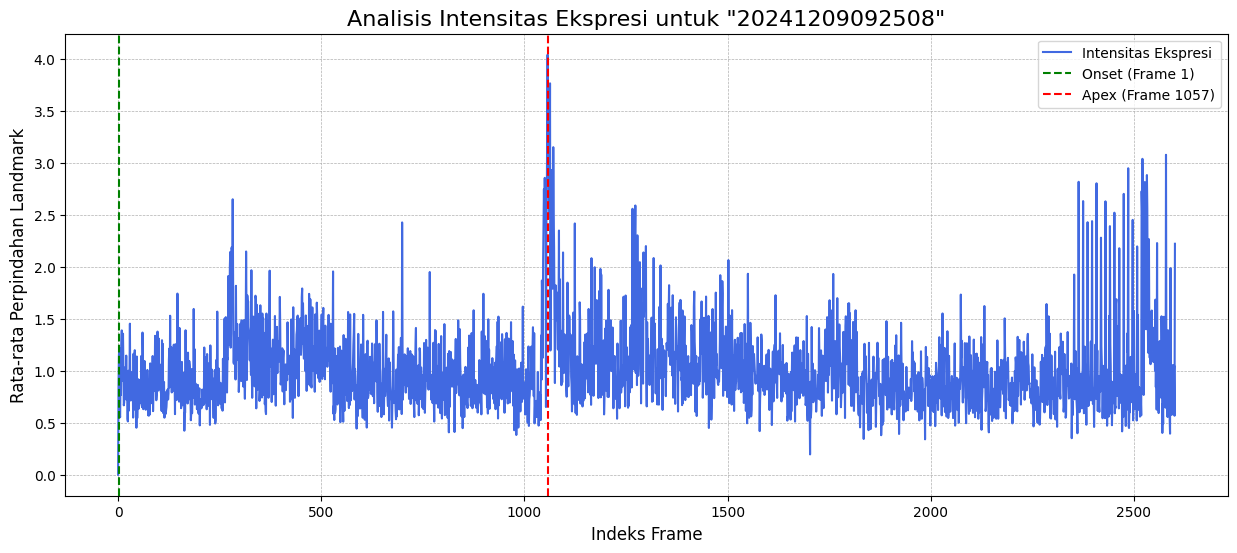

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1057 (Apex).


Analisis di 'Sedang':  40%|████      | 4/10 [03:37<05:21, 53.51s/it]

Berhasil! 1057 frame yang relevan telah disalin.


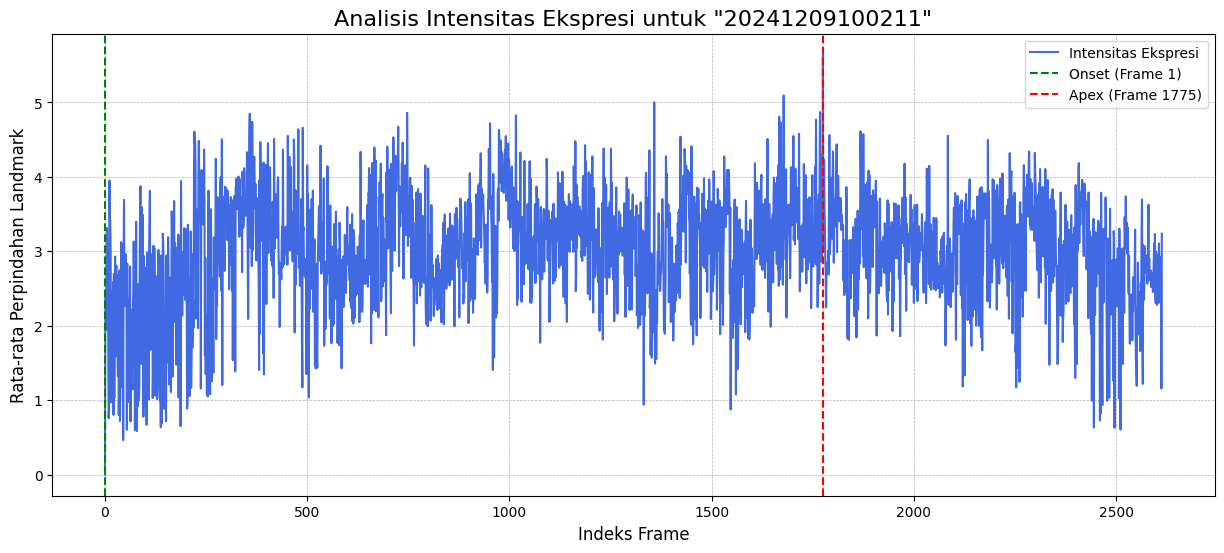

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1775 (Apex).


Analisis di 'Sedang':  50%|█████     | 5/10 [04:27<04:21, 52.35s/it]

Berhasil! 1775 frame yang relevan telah disalin.


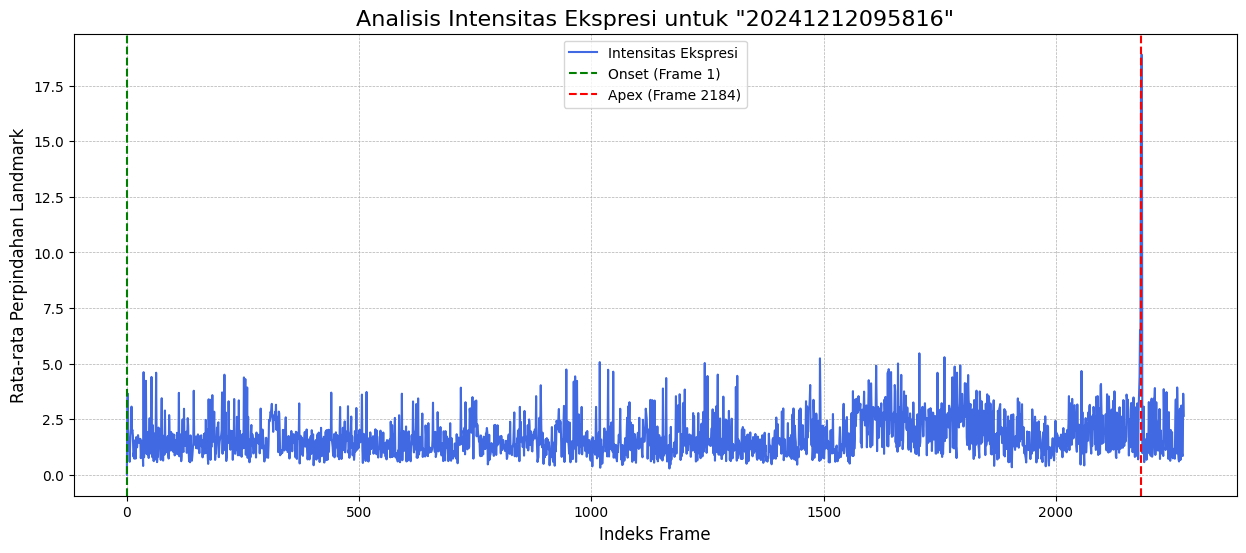

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 2184 (Apex).


Analisis di 'Sedang':  60%|██████    | 6/10 [05:09<03:15, 48.92s/it]

Berhasil! 2184 frame yang relevan telah disalin.


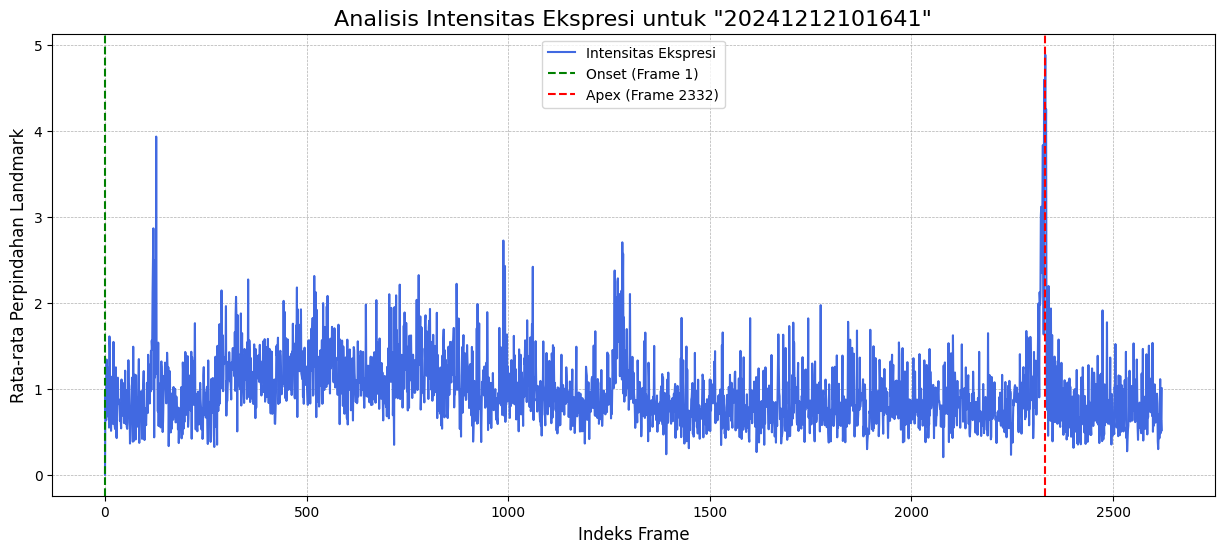

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 2332 (Apex).


Analisis di 'Sedang':  70%|███████   | 7/10 [06:01<02:29, 49.93s/it]

Berhasil! 2332 frame yang relevan telah disalin.


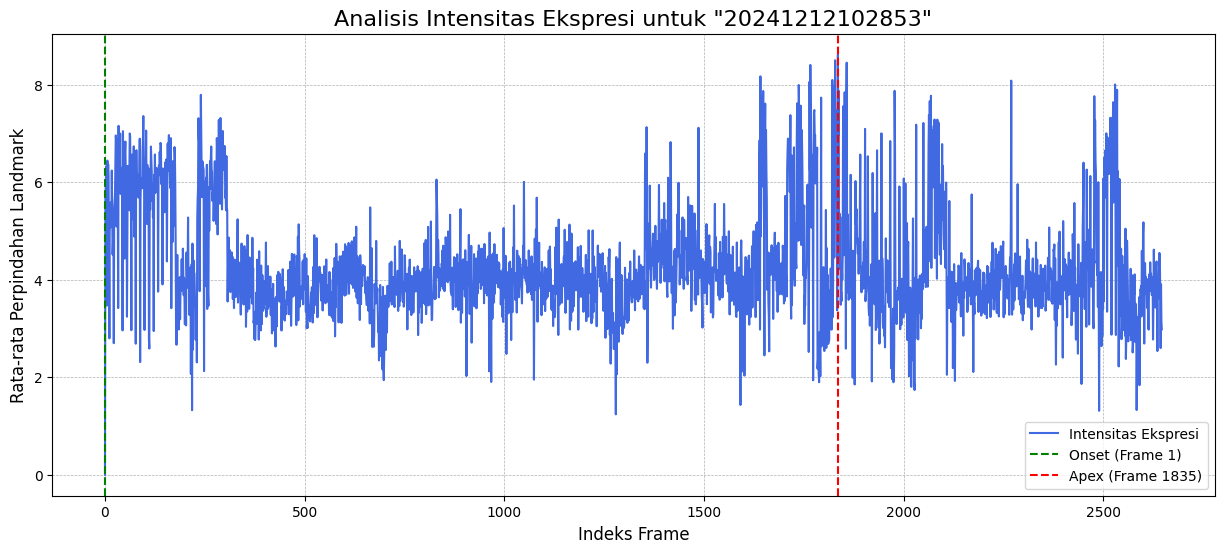

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1835 (Apex).


Analisis di 'Sedang':  80%|████████  | 8/10 [06:48<01:38, 49.06s/it]

Berhasil! 1835 frame yang relevan telah disalin.


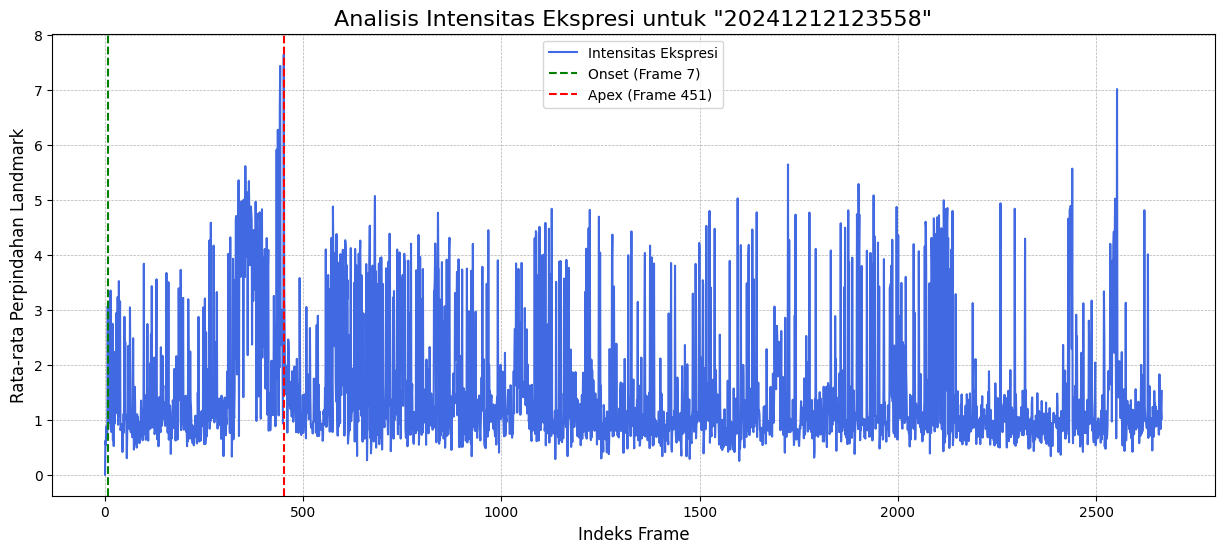

Analisis di 'Sedang':  90%|█████████ | 9/10 [07:44<00:50, 51.00s/it]

[KESIMPULAN] Rentang terdeteksi: Frame 7 (Onset) hingga 451 (Apex).
Berhasil! 445 frame yang relevan telah disalin.


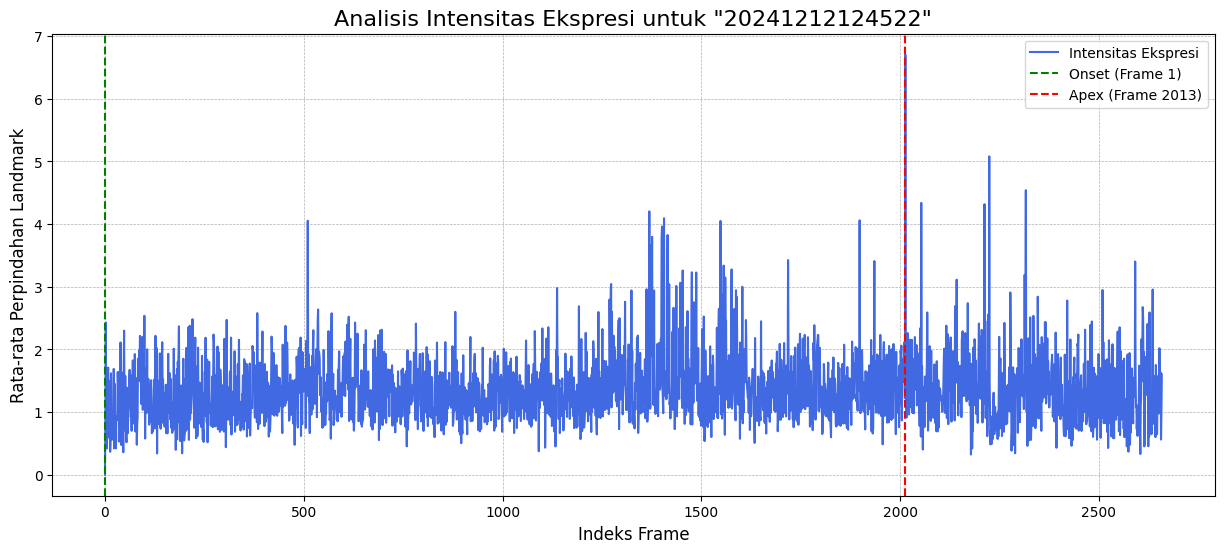

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 2013 (Apex).


Analisis di 'Sedang': 100%|██████████| 10/10 [08:33<00:00, 51.39s/it]


Berhasil! 2013 frame yang relevan telah disalin.

==================== MEMPROSES KATEGORI: RENDAH ====================


Analisis di 'Rendah':   0%|          | 0/10 [00:00<?, ?it/s]

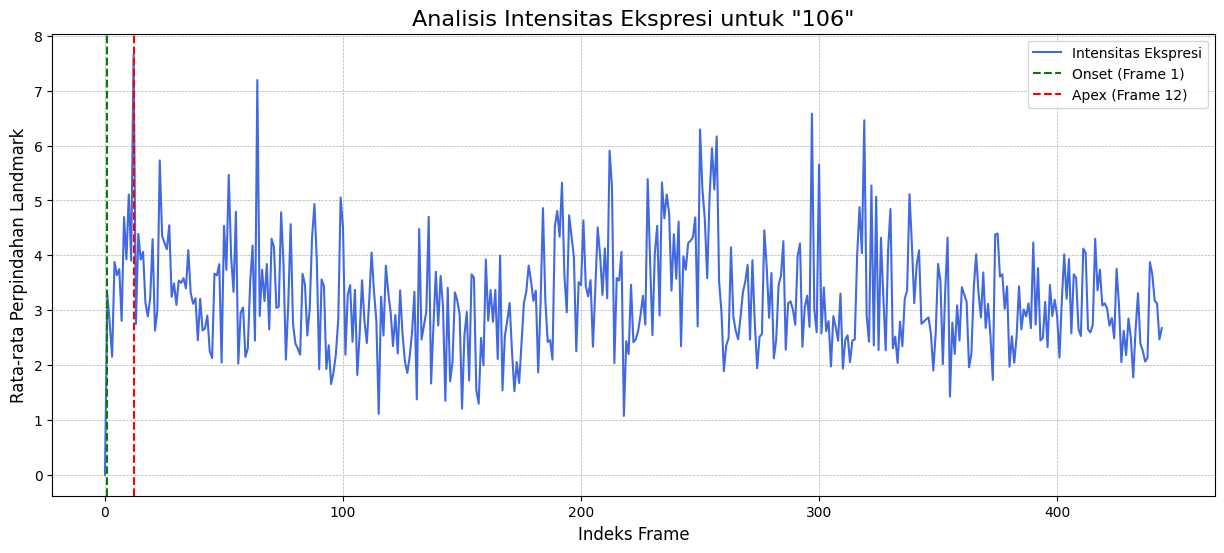

Analisis di 'Rendah':  10%|█         | 1/10 [00:08<01:14,  8.27s/it]

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 12 (Apex).
Berhasil! 12 frame yang relevan telah disalin.


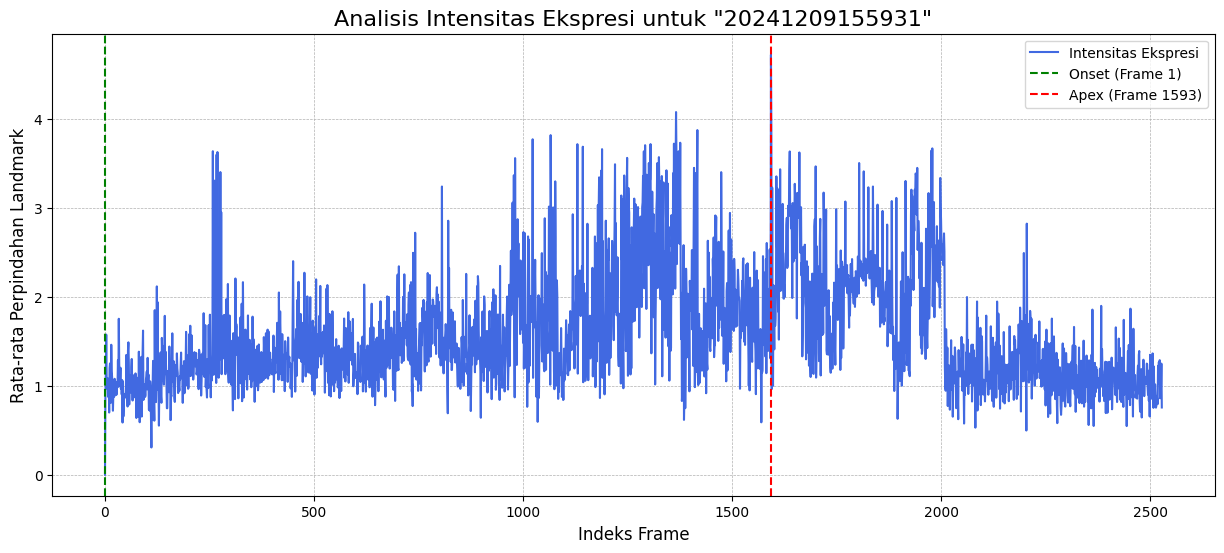

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1593 (Apex).


Analisis di 'Rendah':  20%|██        | 2/10 [00:55<04:10, 31.27s/it]

Berhasil! 1593 frame yang relevan telah disalin.


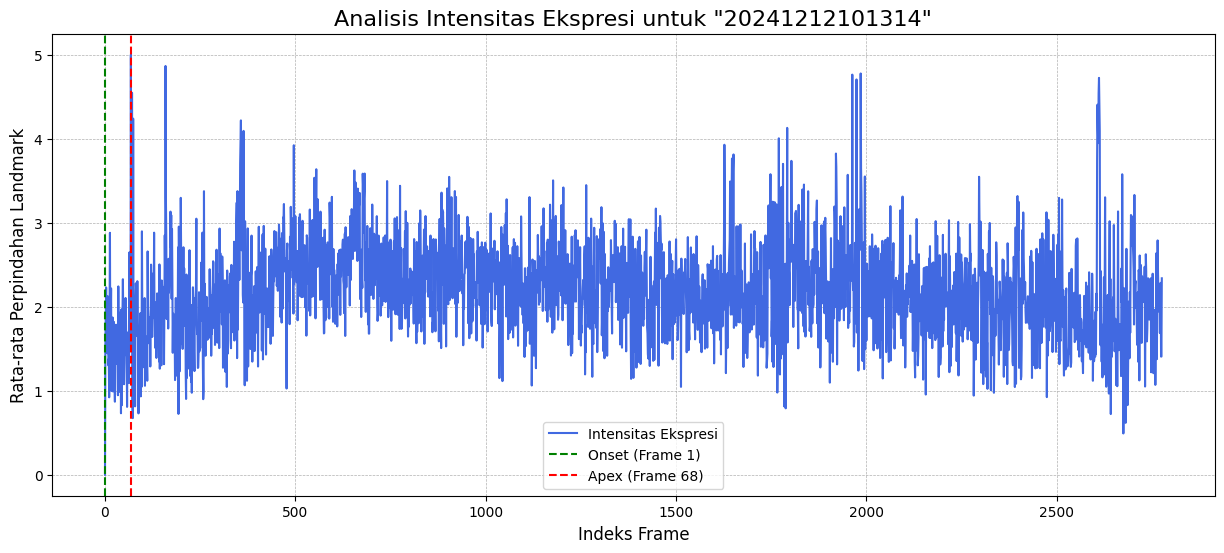

Analisis di 'Rendah':  30%|███       | 3/10 [01:47<04:43, 40.54s/it]

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 68 (Apex).
Berhasil! 68 frame yang relevan telah disalin.


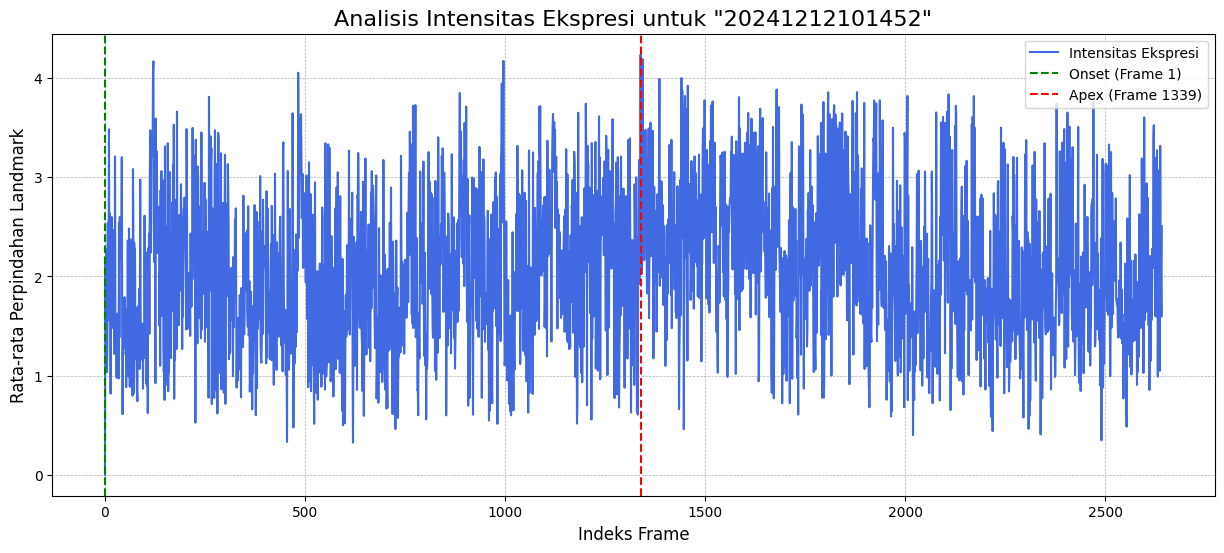

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1339 (Apex).


Analisis di 'Rendah':  40%|████      | 4/10 [02:35<04:22, 43.68s/it]

Berhasil! 1339 frame yang relevan telah disalin.


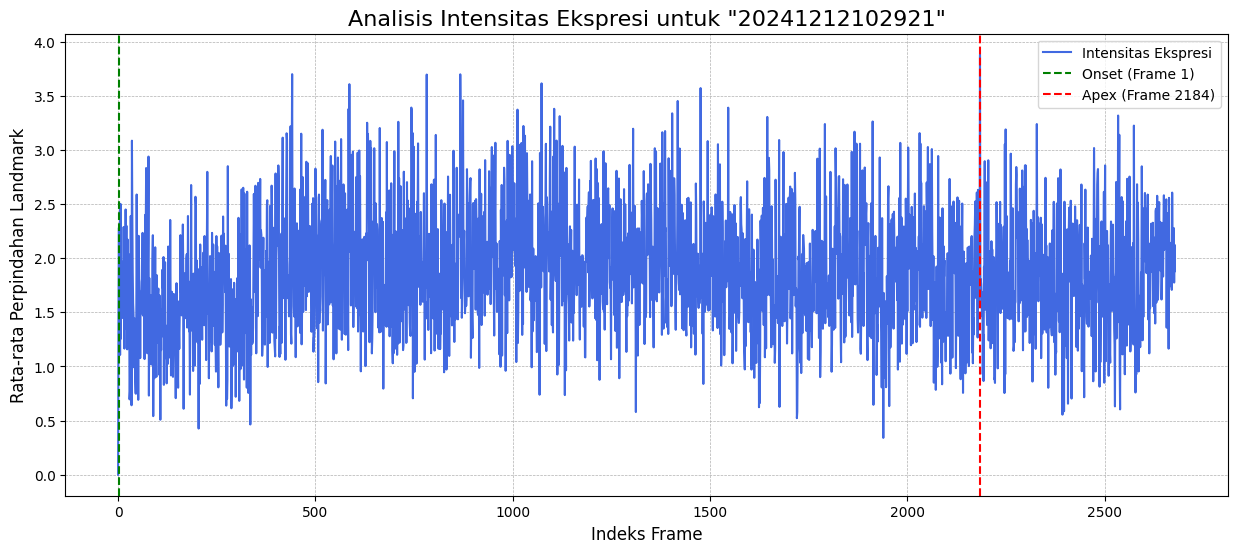

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 2184 (Apex).


Analisis di 'Rendah':  50%|█████     | 5/10 [03:28<03:55, 47.10s/it]

Berhasil! 2184 frame yang relevan telah disalin.


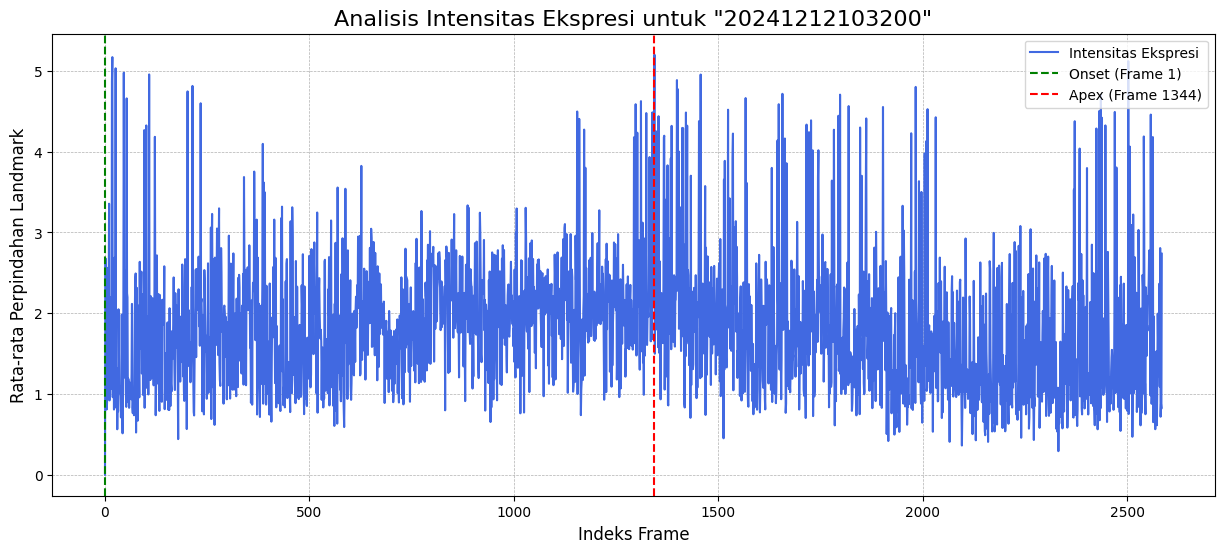

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1344 (Apex).


Analisis di 'Rendah':  60%|██████    | 6/10 [04:20<03:14, 48.61s/it]

Berhasil! 1344 frame yang relevan telah disalin.


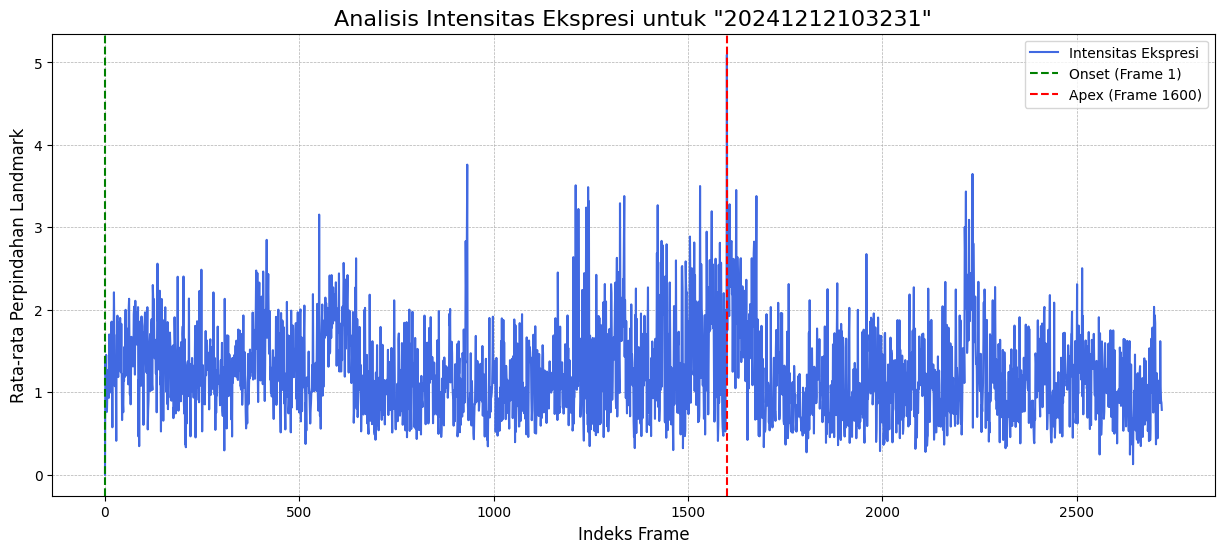

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1600 (Apex).


Analisis di 'Rendah':  70%|███████   | 7/10 [05:17<02:33, 51.33s/it]

Berhasil! 1600 frame yang relevan telah disalin.


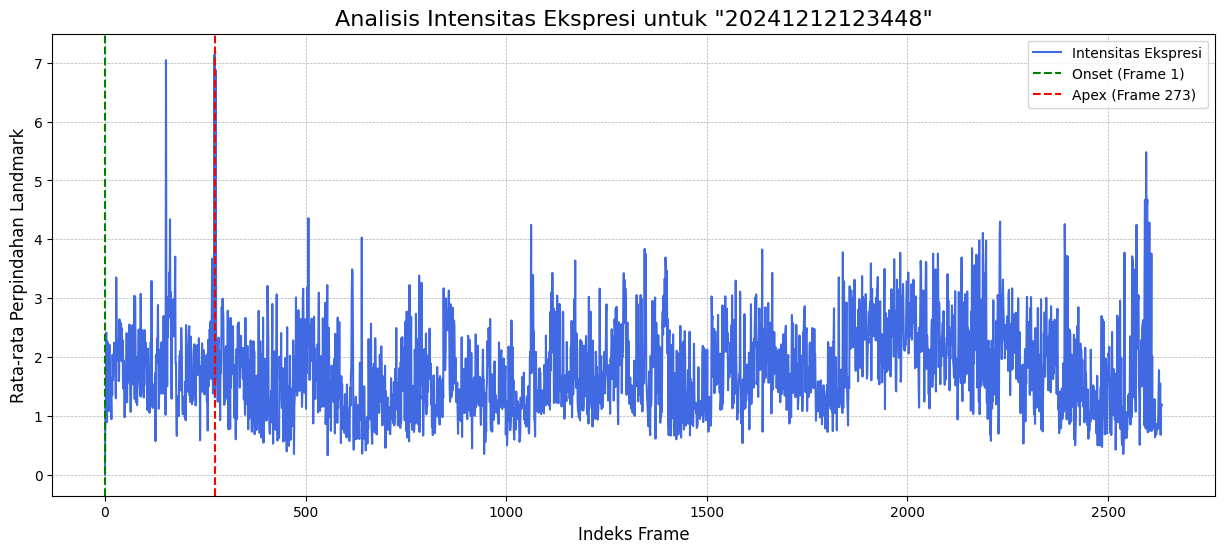

Analisis di 'Rendah':  80%|████████  | 8/10 [06:05<01:40, 50.21s/it]

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 273 (Apex).
Berhasil! 273 frame yang relevan telah disalin.


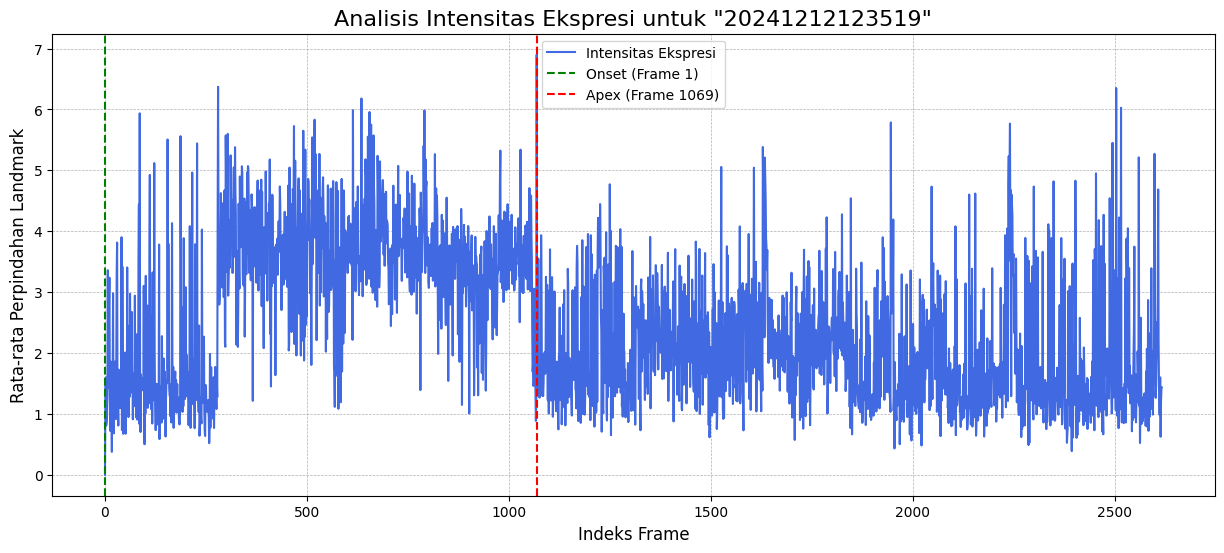

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1069 (Apex).


Analisis di 'Rendah':  90%|█████████ | 9/10 [06:52<00:49, 49.20s/it]

Berhasil! 1069 frame yang relevan telah disalin.


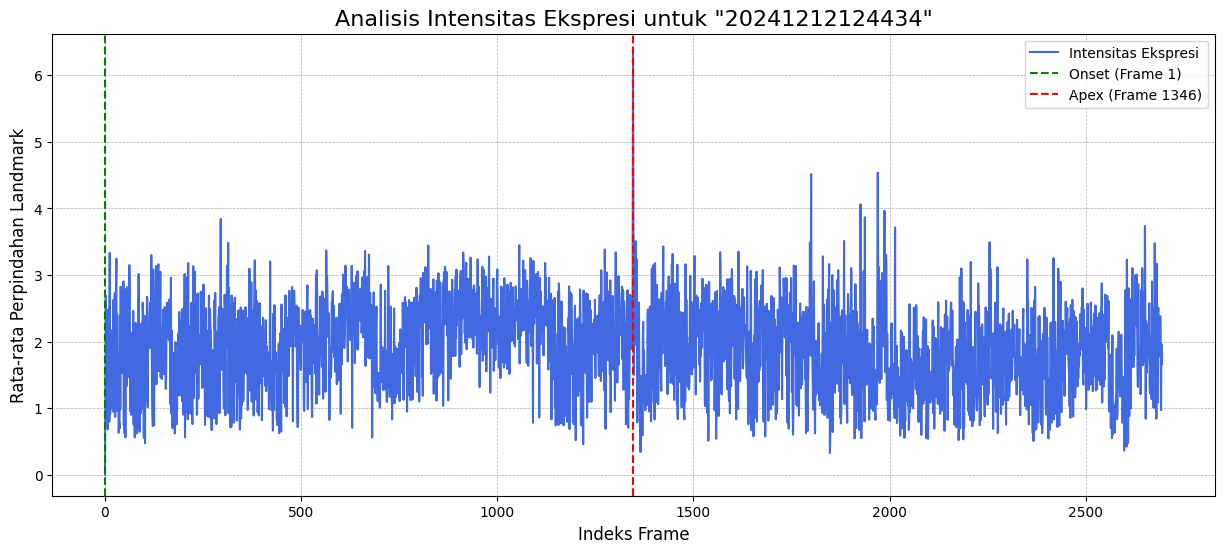

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1346 (Apex).


Analisis di 'Rendah': 100%|██████████| 10/10 [07:41<00:00, 46.16s/it]


Berhasil! 1346 frame yang relevan telah disalin.

==================== MEMPROSES KATEGORI: TINGGI ====================


Analisis di 'Tinggi':   0%|          | 0/9 [00:00<?, ?it/s]

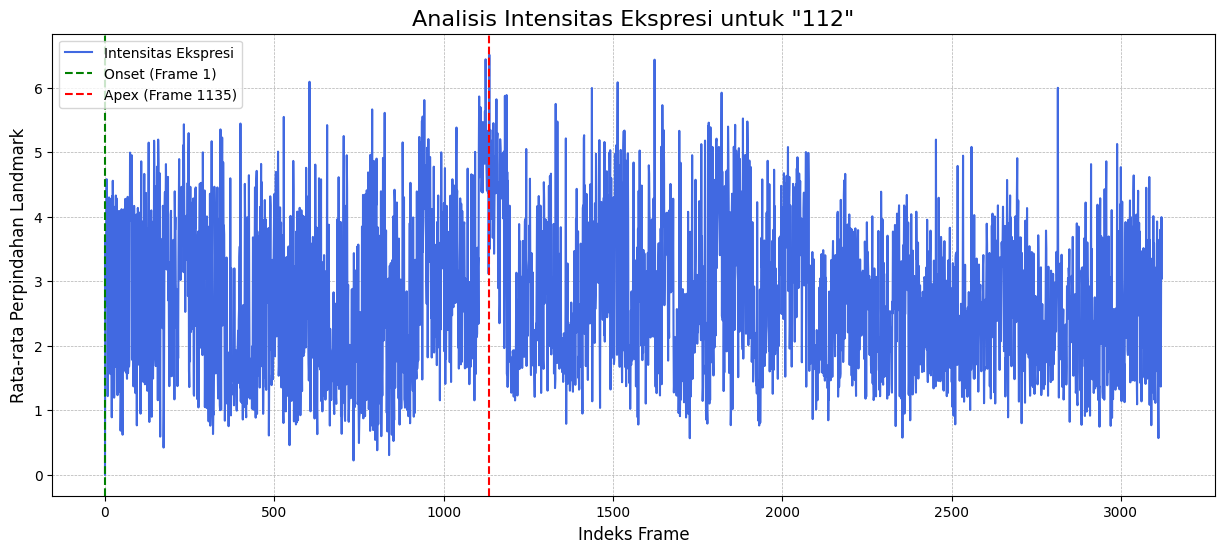

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1135 (Apex).


Analisis di 'Tinggi':  11%|█         | 1/9 [00:58<07:45, 58.21s/it]

Berhasil! 1135 frame yang relevan telah disalin.


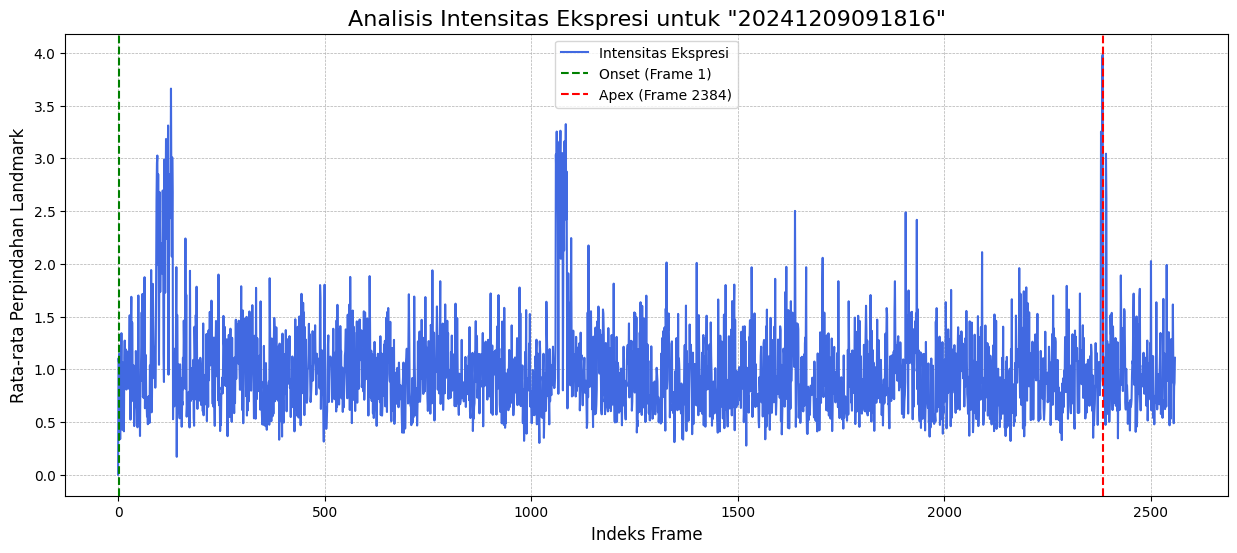

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 2384 (Apex).


Analisis di 'Tinggi':  22%|██▏       | 2/9 [01:48<06:14, 53.52s/it]

Berhasil! 2384 frame yang relevan telah disalin.


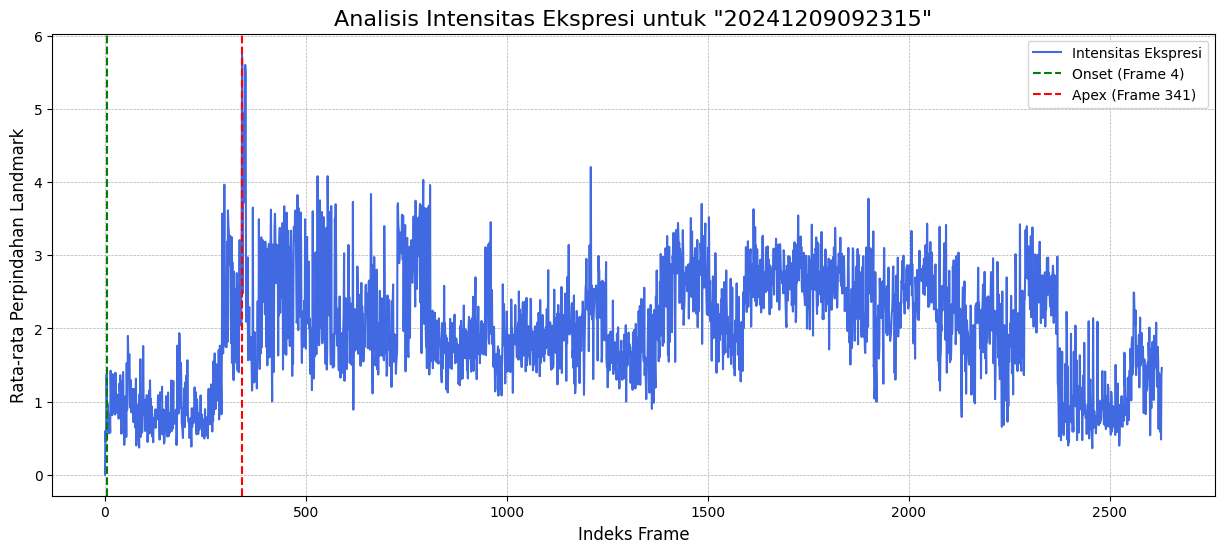

Analisis di 'Tinggi':  33%|███▎      | 3/9 [02:44<05:27, 54.56s/it]

[KESIMPULAN] Rentang terdeteksi: Frame 4 (Onset) hingga 341 (Apex).
Berhasil! 338 frame yang relevan telah disalin.


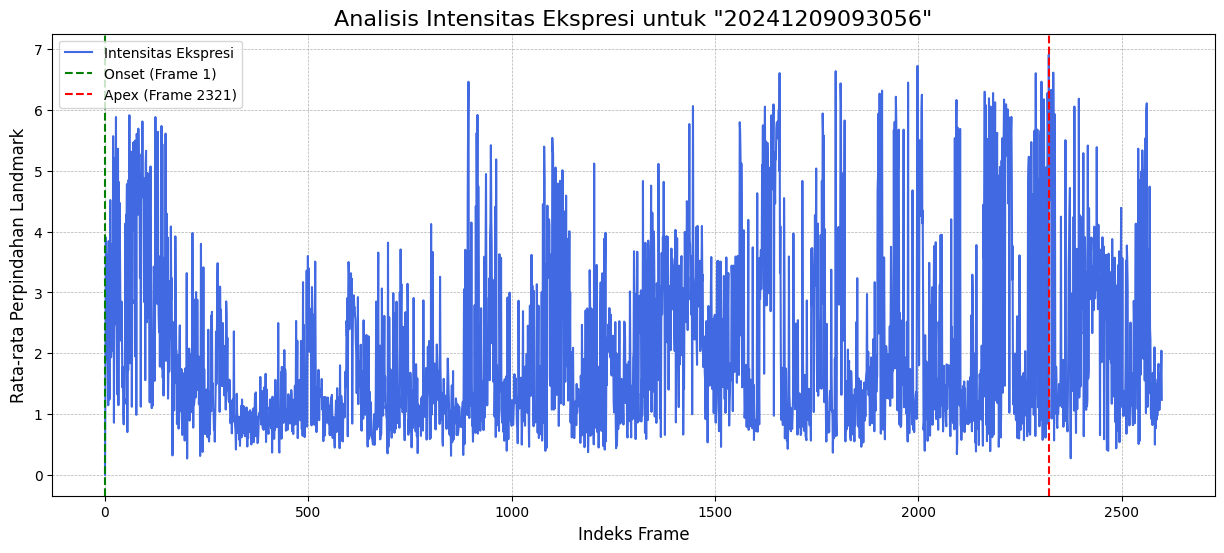

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 2321 (Apex).


Analisis di 'Tinggi':  44%|████▍     | 4/9 [03:35<04:26, 53.21s/it]

Berhasil! 2321 frame yang relevan telah disalin.


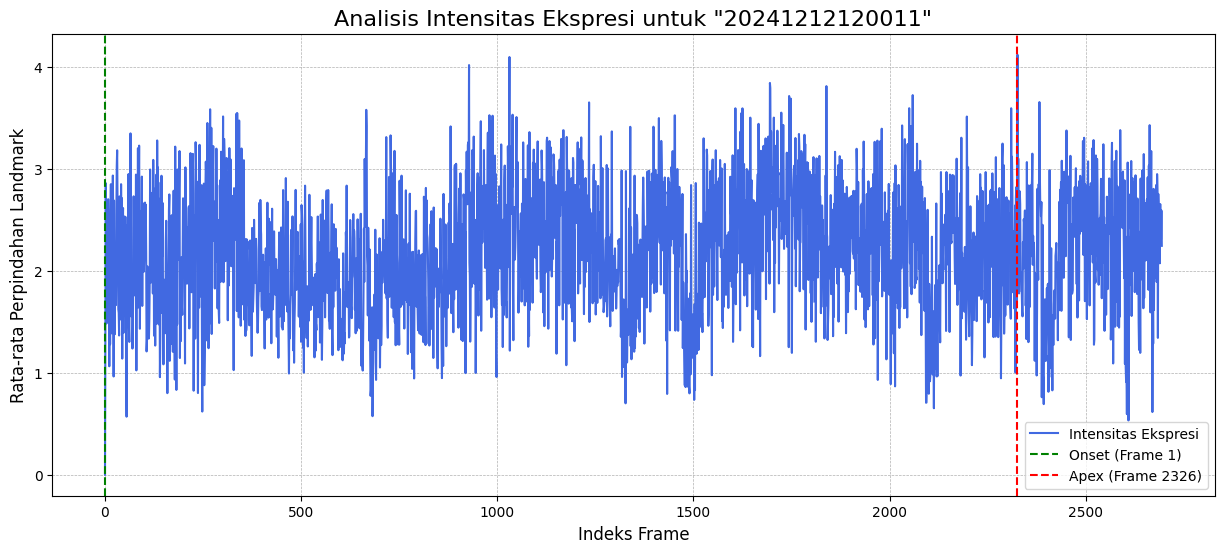

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 2326 (Apex).


Analisis di 'Tinggi':  56%|█████▌    | 5/9 [04:21<03:23, 50.80s/it]

Berhasil! 2326 frame yang relevan telah disalin.


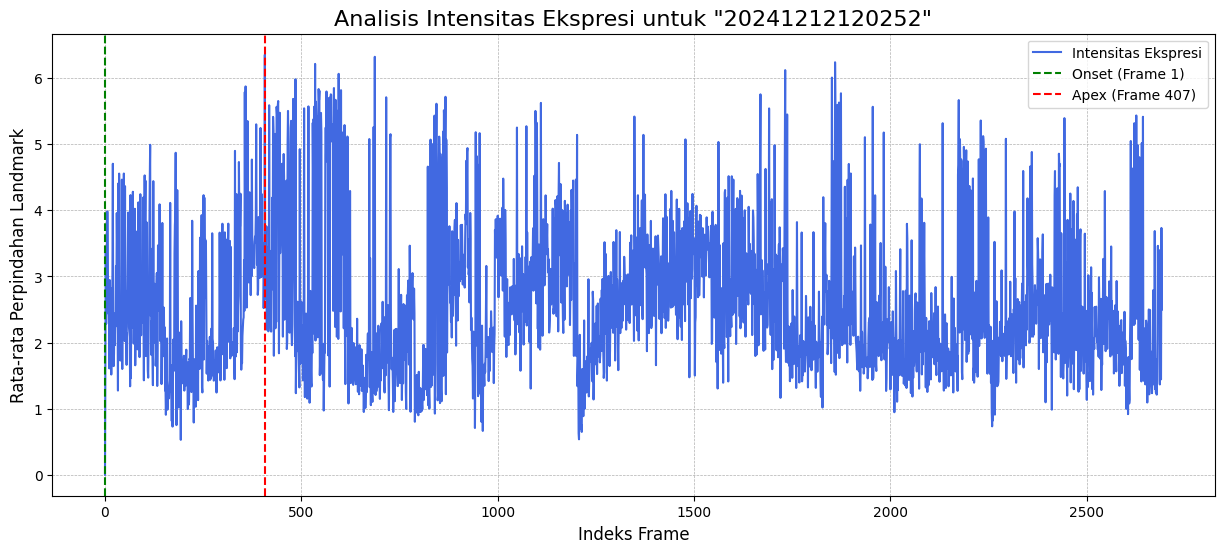

Analisis di 'Tinggi':  67%|██████▋   | 6/9 [05:08<02:28, 49.42s/it]

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 407 (Apex).
Berhasil! 407 frame yang relevan telah disalin.


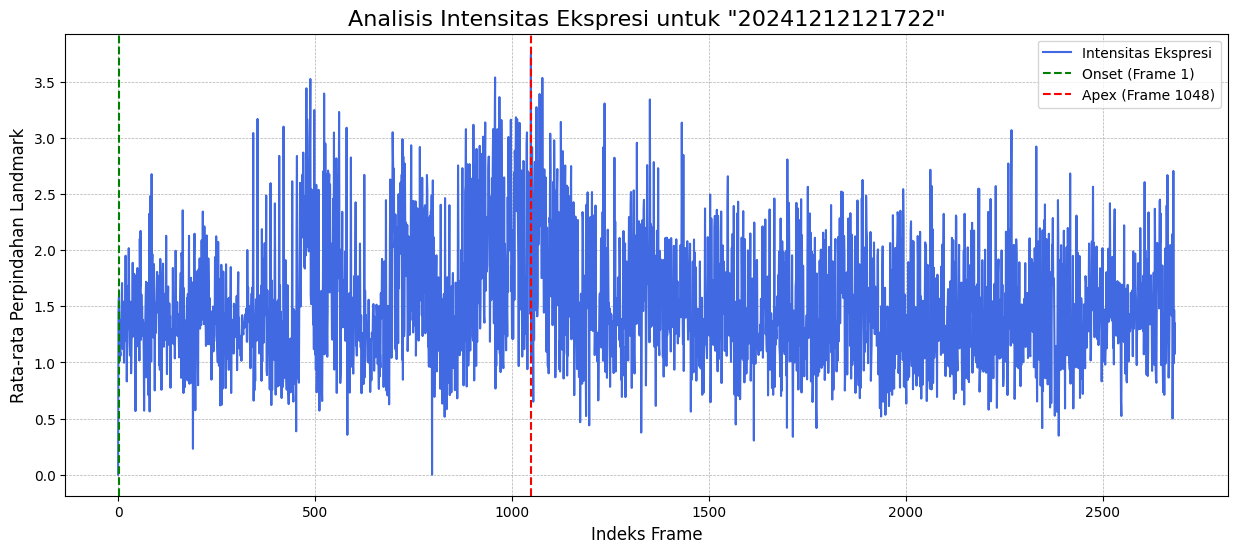

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 1048 (Apex).


Analisis di 'Tinggi':  78%|███████▊  | 7/9 [05:56<01:37, 48.80s/it]

Berhasil! 1048 frame yang relevan telah disalin.


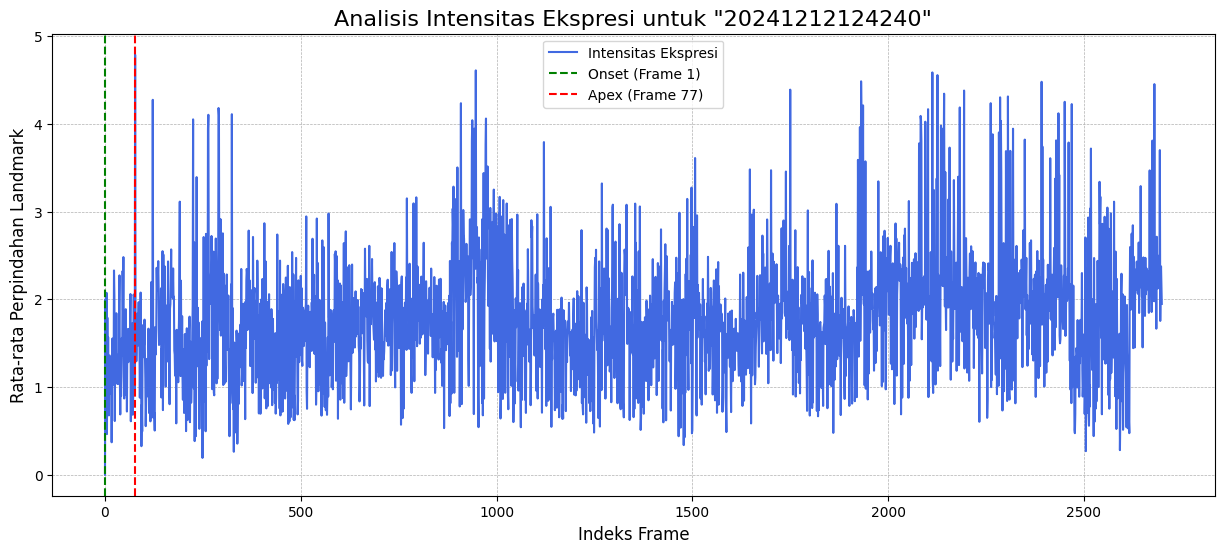

Analisis di 'Tinggi':  89%|████████▉ | 8/9 [06:44<00:48, 48.69s/it]

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 77 (Apex).
Berhasil! 77 frame yang relevan telah disalin.


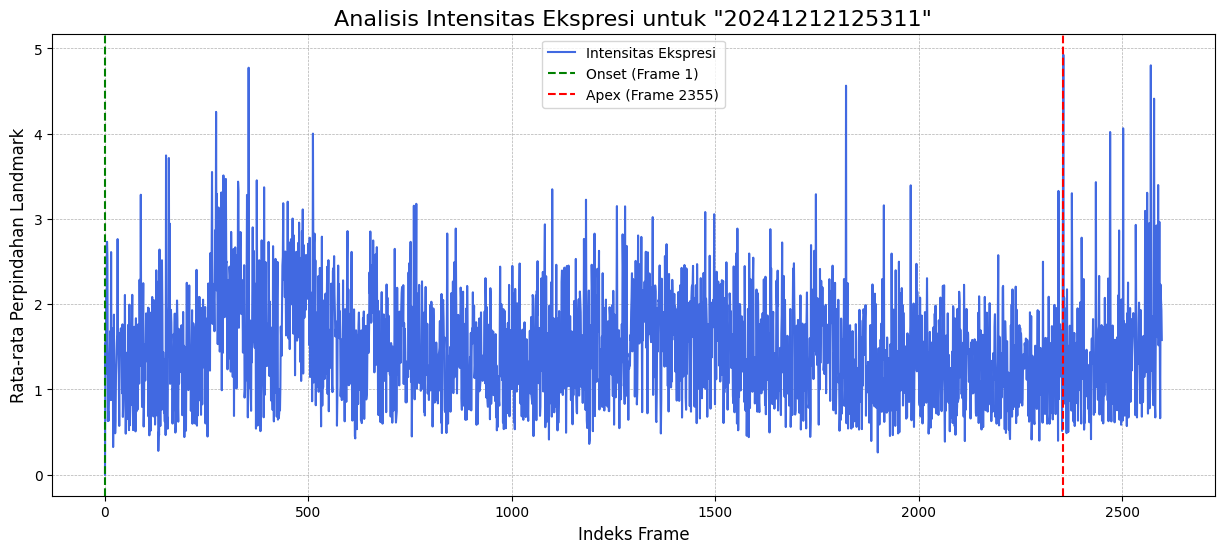

[KESIMPULAN] Rentang terdeteksi: Frame 1 (Onset) hingga 2355 (Apex).


Analisis di 'Tinggi': 100%|██████████| 9/9 [07:33<00:00, 50.38s/it]

Berhasil! 2355 frame yang relevan telah disalin.


✅ Proses otomatisasi untuk semua folder telah selesai!


: 

In [ ]:
face_detector, _ = setup_detector()

if not os.path.isdir(BASE_INPUT_DIR):
    print(f"[ERROR] Direktori masukan '{BASE_INPUT_DIR}' tidak ditemukan.")
else:
    for category_name in os.listdir(BASE_INPUT_DIR):
        category_path = os.path.join(BASE_INPUT_DIR, category_name)
        if not os.path.isdir(category_path):
            continue

        print(f"\n==================== MEMPROSES KATEGORI: {category_name.upper()} ====================")

        output_category_path = os.path.join(OUTPUT_DIR, category_name)
        os.makedirs(output_category_path, exist_ok=True)

        sequence_folders = [d for d in os.listdir(category_path) if os.path.isdir(os.path.join(category_path, d))]

        for sequence_folder_name in tqdm(sequence_folders, desc=f"Analisis di '{category_name}'"):
            input_sequence_path = os.path.join(category_path, sequence_folder_name)
            output_sequence_path = os.path.join(output_category_path, sequence_folder_name)

            analyze_and_visualize(
                    input_path=input_sequence_path,
                    output_path=output_sequence_path,
                    detector=face_detector,
                    threshold=ONSET_INTENSITY_THRESHOLD,
                    resize_dim=RESIZE_DIMENSIONS
                )

    print("\n\n✅ Proses otomatisasi untuk semua folder telah selesai!")

In [ ]:
import torch
import numpy as np
import cv2
from PIL import Image
from facenet_pytorch import MTCNN

# Pilih device: GPU jika tersedia
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Inisialisasi MTCNN dengan opsi keep_all=True untuk mendeteksi banyak wajah
mtcnn = MTCNN(keep_all=True, device=device)

# Fungsi menggambar bounding boxes dan landmark
def draw_boxes_and_landmarks(img_cv2, boxes, landmarks):
    # img_cv2: gambar OpenCV (BGR)
    # boxes: array shape (N,4) [x1,y1,x2,y2]
    # landmarks: array shape (N,5,2) [untuk tiap wajah: 5 titik (x,y)]
    if boxes is not None:
        for i, box in enumerate(boxes):
            x1,y1,x2,y2 = [int(b) for b in box]
            cv2.rectangle(img_cv2, (x1,y1), (x2,y2), (0,255,0), 2)
            # gambar tiap landmark
            for (lx, ly) in landmarks[i]:
                cv2.circle(img_cv2, (int(lx), int(ly)), 3, (0,0,255), -1)
    return img_cv2

# Path ke gambar
img_path = '../testing_output/Rendah/106/frame_second_1_frame_0_face_0.png'
# Buka gambar via PIL and convert ke RGB
img_pil = Image.open(img_path).convert('RGB')

# Deteksi wajah + landmark
boxes, probs, landmarks = mtcnn.detect(img_pil, landmarks=True)

print("Boxes:", boxes)
print("Landmarks:", landmarks)  # bentuk (N,5,2) untuk N wajah

# Konversi ke format cv2 untuk menggambar (OpenCV memakai BGR)
img_np = np.array(img_pil)
img_cv2 = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)

# Gambar
img_drawn = draw_boxes_and_landmarks(img_cv2, boxes, landmarks)

# Tampilkan hasil
cv2.imshow('Detected Faces & Landmarks', img_drawn)
cv2.waitKey(0)
cv2.destroyAllWindows()

# Simpan hasil jika mau
cv2.imwrite('hasil_deteksi.jpg', img_drawn)


/home/ryuko/Documents/Codes/Python/Skripsi/Convat-1st/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Boxes: [[90.1343994140625 95.23179626464844 272.8008117675781 313.3979797363281]]
Landmarks: [[[137.13833618164062 186.09744262695312]
  [223.6792755126953 182.8974609375]
  [177.11227416992188 209.56362915039062]
  [141.53184509277344 262.56805419921875]
  [221.7458038330078 258.8143005371094]]]
